# 04. Model Evaluation: In-Depth Cybersecurity Analysis

## Security Metrics & Confusion Matrix Interpretation
In an endpoint or network detection setting, the confusion matrix elements carry profound real-world consequences:

| Metric | Term | Cybersecurity Meaning & Real-World Impact |
| :--- | :--- | :--- |
| **True Positive (TP)** | Malware Detected | A malicious PE was correctly identified and stopped. |
| **True Negative (TN)** | Clean File Allowed | A benign program was allowed to execute without disruption. |
| **False Positive (FP)** | Benign File Flagged | A safe program was blocked. Causes IT disruption and analyst fatigue. |
| **False Negative (FN)** | **Missed Malware** | **Critical Security Failure.** Malware breached defenses and executed! |

> **Why False Negatives are the Most Dangerous:**
> A false positive causes a nuisance alert. In contrast, a **false negative means ransomware, a rootkit, or a remote access trojan went undetected**, leading to data exfiltration, business disruption, or network compromise.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ember
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

PROJECT_ROOT = os.path.abspath(os.path.join(".."))
DATASET_DIR = os.path.join(PROJECT_ROOT, "dataset", "ember2018")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

# Load test set & models
_, _, X_test, y_test = ember.read_vectorized_features(DATASET_DIR)
preprocessor = joblib.load(os.path.join(MODELS_DIR, "preprocessor.pkl"))
X_test_scaled = preprocessor.transform(X_test)

models = {
    "Random Forest": (joblib.load(os.path.join(MODELS_DIR, "random_forest.pkl")), X_test),
    "Logistic Regression": (joblib.load(os.path.join(MODELS_DIR, "logistic_regression.pkl")), X_test_scaled),
    "LightGBM": (joblib.load(os.path.join(MODELS_DIR, "lightgbm.pkl")), X_test),
}
print(f"Loaded test dataset: {len(y_test):,} samples ({np.sum(y_test==0):,} Benign, {np.sum(y_test==1):,} Malicious)")


Loaded test dataset: 5,000 samples (2,500 Benign, 2,500 Malicious)


## Classification Reports for All Models

In [2]:
for name, (model, X) in models.items():
    preds = model.predict(X)
    print(f"================== {name} Classification Report ==================")
    print(classification_report(y_test, preds, target_names=["Benign (0)", "Malicious (1)"], digits=4))


================== Random Forest Classification Report ==================
               precision    recall  f1-score   support

   Benign (0)     0.8529    0.7280    0.7855      2500
Malicious (1)     0.7627    0.8744    0.8148      2500

     accuracy                         0.8012      5000
    macro avg     0.8078    0.8012    0.8001      5000
 weighted avg     0.8078    0.8012    0.8001      5000



================== Logistic Regression Classification Report ==================
               precision    recall  f1-score   support

   Benign (0)     0.7711    0.5876    0.6670      2500
Malicious (1)     0.6669    0.8256    0.7378      2500

     accuracy                         0.7066      5000
    macro avg     0.7190    0.7066    0.7024      5000
 weighted avg     0.7190    0.7066    0.7024      5000

================== LightGBM Classification Report ==================


               precision    recall  f1-score   support

   Benign (0)     0.7476    0.3672    0.4925      2500
Malicious (1)     0.5806    0.8760    0.6983      2500

     accuracy                         0.6216      5000
    macro avg     0.6641    0.6216    0.5954      5000
 weighted avg     0.6641    0.6216    0.5954      5000



## Confusion Matrix Visualizations

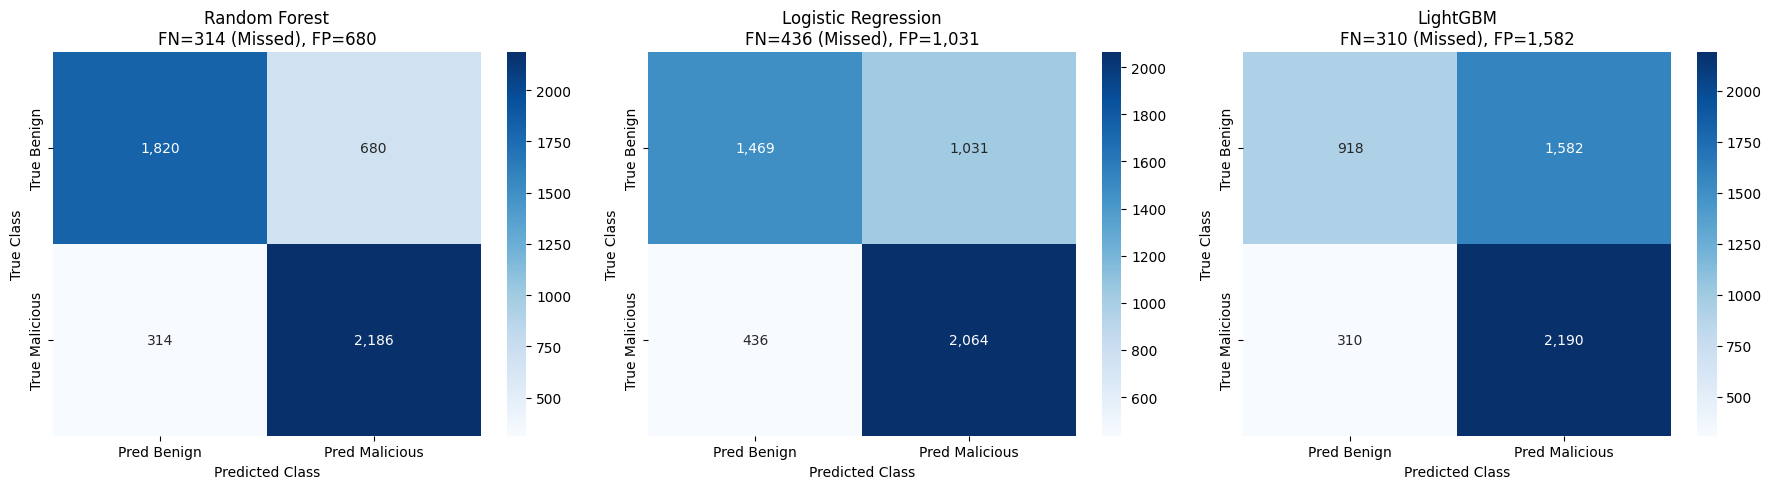

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, (model, X)) in enumerate(models.items()):
    preds = model.predict(X)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[idx],
                xticklabels=["Pred Benign", "Pred Malicious"],
                yticklabels=["True Benign", "True Malicious"])
    axes[idx].set_title(f"{name}\nFN={fn:,} (Missed), FP={fp:,}")
    axes[idx].set_ylabel("True Class")
    axes[idx].set_xlabel("Predicted Class")

plt.tight_layout()
plt.show()


## ROC Curves & Comparative AUC Analysis

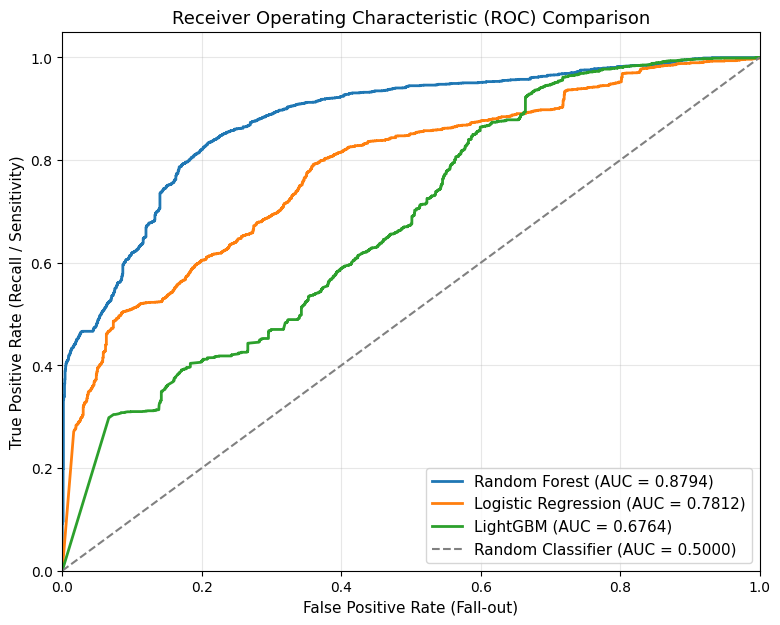

In [4]:
plt.figure(figsize=(9, 7))

for name, (model, X) in models.items():
    probs = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--", label="Random Classifier (AUC = 0.5000)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (Fall-out)", fontsize=11)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11)
plt.title("Receiver Operating Characteristic (ROC) Comparison", fontsize=13)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()


## Comprehensive Metrics Comparison Table

In [5]:
comp_records = []
for name, (model, X) in models.items():
    preds = model.predict(X)
    probs = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    
    comp_records.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "Detection Rate": round(tp / (tp + fn), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4),
        "False Pos Rate (FPR)": round(fp / (fp + tn), 4),
        "False Neg Rate (FNR)": round(fn / (fn + tp), 4),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

df_comp = pd.DataFrame(comp_records).sort_values(by="F1-Score", ascending=False)
display(df_comp)


,Model,Accuracy,Precision,Recall,Detection Rate,F1-Score,ROC-AUC,False Pos Rate (FPR),False Neg Rate (FNR),TN,FP,FN,TP
0,Random Forest,0.8012,0.7627,0.8744,0.8744,0.8148,0.8794,0.2720,0.1256,1820,680,314,2186
1,Logistic Regression,0.7066,0.6669,0.8256,0.8256,0.7378,0.7812,0.4124,0.1744,1469,1031,436,2064
2,LightGBM,0.6216,0.5806,0.8760,0.8760,0.6983,0.6764,0.6328,0.1240,918,1582,310,2190


## Explainable AI (XAI): Top Static Features Influencing Random Forest

,Rank,Feature,Index,Importance
0,#1,header[0],626,0.04226
1,#2,header[11],637,0.01856
2,#3,byteentropy[250],506,0.01768
3,#4,byteentropy[246],502,0.01381
4,#5,byteentropy[243],499,0.01351
5,#6,histogram[90],90,0.01312
6,#7,histogram[151],151,0.01189
7,#8,byteentropy[245],501,0.01162
8,#9,byteentropy[254],510,0.01150
9,#10,strings[84],596,0.01115


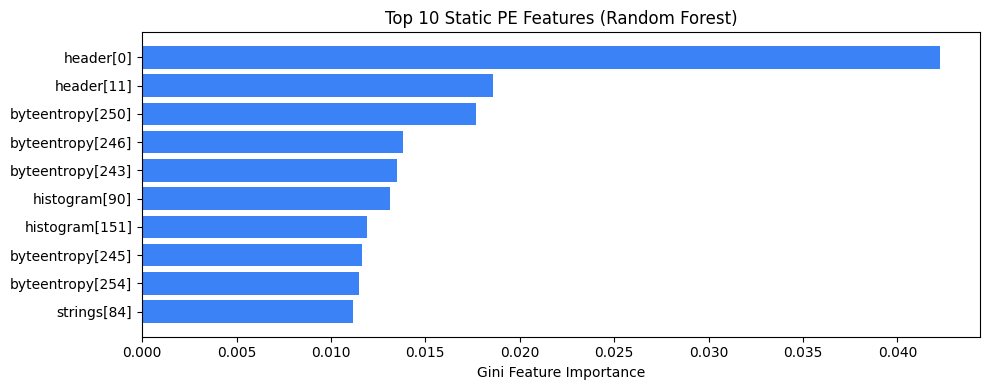

In [6]:
rf_model, _ = models["Random Forest"]
extractor = ember.PEFeatureExtractor(2)
feature_names = []
for fe in extractor.features:
    for i in range(fe.dim):
        feature_names.append(f"{fe.name}[{i}]")

importances = rf_model.feature_importances_
top_idx = np.argsort(importances)[::-1][:10]

xai_df = pd.DataFrame([
    {"Rank": f"#{rank}", "Feature": feature_names[i], "Index": i, "Importance": round(importances[i], 5)}
    for rank, i in enumerate(top_idx, 1)
])
display(xai_df)

# Visual bar chart of top features
plt.figure(figsize=(10, 4))
plt.barh([feature_names[i] for i in top_idx[::-1]], [importances[i] for i in top_idx[::-1]], color="#3b82f6")
plt.xlabel("Gini Feature Importance")
plt.title("Top 10 Static PE Features (Random Forest)")
plt.tight_layout()
plt.show()
